# Mixed Nucleic Acid Systems: RNA Input, DNA Gate, and RNase H

This notebook models a mixed nucleic acid system incorporating enzymatic degradation and discontinuous simulations, based on examples from the literature Dissipative Control over the Toehold-Mediated DNA Strand Displacement Reaction ([Del Grosso et al. *Angew. Chem. Int. Ed.* 2022](https://onlinelibrary.wiley.com/doi/full/10.1002/anie.202201929)). 

## Simulation:
RNA Input (I{5}) is spiked into the system at a 1x concentration (100 nmol L⁻¹) approximately every hour, reacting with a Reporter via the `TMSE()` mechanism to generate a signal. RNase H then degrades the RNA within the resulting RNA:DNA duplex, reversing the signal to create a measurable pulse. 
We model this enzymatic degradation using two different approaches:
* [Basic Kinetics](Modeling-with-`BasicCatalysis()`): Models the RNase H degradation using the built-in BioCRNpyler `BasicCatalysis()` mechanism.
* [Michaelis-Menten Kinetics](#Modeling-with-`MichaelisMenten()`): Models the RNase H degradation using the more detailed `MichaelisMenten()` mechanism.

*Note: The RNase H inhibition by RNA waste fragments is omitted from original reaction.*

# Dependencies and packages

In [1]:
from biocrnpyler import *
import numpy as np
import pylab as plt
from matplotlib.ticker import FormatStrFormatter
from pathlib import Path

# Get base directory for BioCRNpyler scripts
directory = Path.cwd()
for p in [directory, *directory.parents]:
    if p.name == 'TMSE_BioCRNpyler_Library':
        base_dir = p
        break

# Location of scripts
tmse_mechs = (base_dir / 'mechanisms' / 'ToeholdMediatedStrandExchange.py').as_posix()
tmse_comps = (base_dir / 'components' / 'ToeholdMediatedStrandExchange.py').as_posix()
rna_comp = (base_dir / 'components' / 'RNAassembly.py').as_posix()

# Run scripts
%run {tmse_mechs}
%run {tmse_comps}
%run {rna_comp}

# Directory for Figures and Data
figs_dir = (base_dir / 'figures').as_posix()
data_dir = (base_dir / 'data').as_posix()

## Global variables and definitions

In [2]:
# Simulate all models - example for 6 hours
timepoints = np.linspace(0,6,1001)*3600 

# Set a global default size for plots
plt.rcParams["figure.figsize"] = (6, 6)
font = 'MS Reference Sans Serif'
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams['font.sans-serif'] = ['MS Reference Sans Serif']


#Definition to un-nest lists that will be created by models
def flatten(t):
    return [item for sublist in t for item in sublist]

# Plotting format
def FormatPlot(ylabel, fig_name, ymin = -0.02, ymax = 100):
    fs = 20
    
    plt.ylabel(ylabel,fontsize=fs)
    plt.xlabel('Time (h)',fontsize=fs)
    plt.legend(title='Input',frameon=False, 
               title_fontsize = fs-4, fontsize=fs-4)

    plt.ylim(ymin,ymax)
    plt.xlim(0,6)
    plt.xticks(ticks=[0,1,2,3,4,5,6],fontsize=fs)
    plt.yticks(ticks=[0.0,0.2,0.4,0.6,0.8,1.0],fontsize=fs)
    
    # Setting the same number of decimal places for y-axis
    ax1 = plt.gca()
    ax1.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))

    
    # Save plot as svg
    plt.savefig(f'{figs_dir}/SI_{fig_name}.svg')

# Modeling with `BasicCatalysis()`

In [3]:
# Define initial DNA and Reporter DNA
sim_inputs_rna = {'Input{k,i,}': ['Input', 'k','i']} # RNA
sim_inputs_dna = {'G{i,j}':['Gate','i', 'j']} # DNA

# Components
sd_rna = StrandExchangeMol(sim_inputs_rna, material_type = 'rna')
sd_dna = StrandExchangeMol(sim_inputs_dna, material_type = 'dna')

tmse_mols = sd_dna.mol+sd_rna.mol
step_sd = TMSE(tmse_mols)

# RNase activity
dna_ss = step_sd.outputs[0]
comp_DNA = Species(dna_ss.name, material_type = 'dna', attributes = ['c'])
rna_frag = Species('rna_frag')
rnaseH = Enzyme('RNAseH', step_sd.gateouts, [comp_DNA, rna_frag]) 

# Enxyme mechanism
mech_cat = BasicCatalysis()
cat_mechanisms = {mech_cat.mechanism_type:mech_cat}
# Mechanism strand displacement
mech_sd = OneStepTMSE()
sd_mechanisms = {mech_sd.mechanism_type:mech_sd}

# Parameters
specific_parameters = {"kx":1.5e5/1e9, 
                       "krev":0,
                       "kcat":1.2e-6
                       } 

# Make Mixture and Compile
M_pulse = Mixture("TMSE_wMixedna", 
                 components=[rnaseH, step_sd],
                 parameters=specific_parameters,
                 mechanisms=cat_mechanisms|sd_mechanisms)

# Compile the CRN with Mixture.compile_crn
CRN_pulse = M_pulse.compile_crn()

#Add reaction for DNA rebinding
rxnB = Reaction.from_massaction(inputs = [comp_DNA,step_sd.outputs],
                                outputs = [sd_dna.mol[0]],
                                k_forward = .0035) 

CRN_pulse.add_reactions([rxnB])

print(CRN_pulse.pretty_print(show_rates = True, show_attributes = True, 
                             show_materials = True, show_keys = False))


Species(N = 7) = {
rna_frag (@ 0),  protein[RNAseH] (@ 0),  dna[Output_i_j(ss)] (@ 0),  dna[Output_i_j(c)] (@ 0),  rna[Input_k_i] (@ 0),  dna[Gate_i_j] (@ 0),  rnadna[GateOut_k_i] (@ 0),  
}

Reactions (3) = [
0. protein[RNAseH]+rnadna[GateOut_k_i] --> protein[RNAseH]+dna[Output_i_j(c)]+rna_frag
 Kf=k_forward * protein_RNAseH * rnadna_GateOut_k_i
  k_forward=1.2e-06

1. dna[Gate_i_j]+rna[Input_k_i] --> dna[Output_i_j(ss)]+rnadna[GateOut_k_i]
 Kf=k_forward * dna_Gate_i_j * rna_Input_k_i
  k_forward=0.00015

2. dna[Output_i_j(c)]+dna[Output_i_j(ss)] --> dna[Gate_i_j]
 Kf=k_forward * dna_Output_i_j_c * dna_Output_i_j_ss
  k_forward=0.0035

]


error spot 2
protein_RNAseH
rnadna_GateOut_k_i
dna_Output_i_j_c
rna_frag
rna_Input_k_i
dna_Gate_i_j
dna_Output_i_j_ss
time
error spot 2
protein_RNAseH
rnadna_GateOut_k_i
dna_Output_i_j_c
rna_frag
rna_Input_k_i
dna_Gate_i_j
dna_Output_i_j_ss
time
error spot 2
protein_RNAseH
rnadna_GateOut_k_i
dna_Output_i_j_c
rna_frag
rna_Input_k_i
dna_Gate_i_j
dna_Output_i_j_ss
time
error spot 2
protein_RNAseH
rnadna_GateOut_k_i
dna_Output_i_j_c
rna_frag
rna_Input_k_i
dna_Gate_i_j
dna_Output_i_j_ss
time
error spot 2
protein_RNAseH
rnadna_GateOut_k_i
dna_Output_i_j_c
rna_frag
rna_Input_k_i
dna_Gate_i_j
dna_Output_i_j_ss
time
error spot 2
protein_RNAseH
rnadna_GateOut_k_i
dna_Output_i_j_c
rna_frag
rna_Input_k_i
dna_Gate_i_j
dna_Output_i_j_ss
time
error spot 2
protein_RNAseH
rnadna_GateOut_k_i
dna_Output_i_j_c
rna_frag
rna_Input_k_i
dna_Gate_i_j
dna_Output_i_j_ss
time
error spot 2
protein_RNAseH
rnadna_GateOut_k_i
dna_Output_i_j_c
rna_frag
rna_Input_k_i
dna_Gate_i_j
dna_Output_i_j_ss
time
error spot 2
pro

C:\Users\zej1\AppData\Local\Temp\ipykernel_22948\4128991096.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Input',frameon=False,


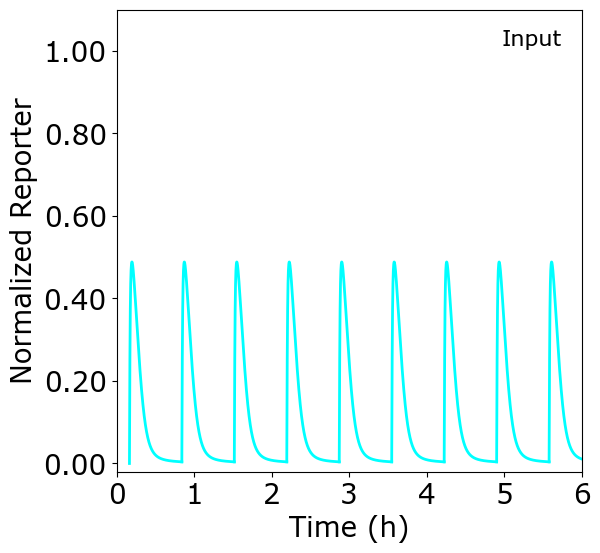

In [4]:
# Simulate
try:
    # import numpy as np
    import pylab as plt
    
    t_max = 400
    t_start = 10/60 #hr
    t_now = t_start

    while t_now < t_max:
        # Simulating the model - example for 1 hours
        timepoints_2 = np.linspace(t_now,t_now+1,1001)*3600 

        # Create an initial condition so A has a non-zero value
        if t_now==t_start:
            initial_concentration_dict = {'rna_Input_k_i': 100, 'dna_Gate_i_j':50,
                                          'protein_RNAseH': 8530}

        else:
            # new_ic_dict = {}
            for col in R_t.columns:
                molecule = col
                print(molecule)
                if col == 'rna_Input_k_i':
                    value= R_t[col][1]+100
                    initial_concentration_dict.update({molecule: value})
                elif col !='time':
                    value= R_t[col][1]
                    initial_concentration_dict.update({molecule: value})
        
        # This function can also take a filename keyword to save the file at the same time
        R = CRN_pulse.simulate_with_bioscrape_via_sbml(timepoints = timepoints_2,
                                                       initial_condition_dict = initial_concentration_dict)
        R_t = R[(R['rna_Input_k_i']<=0.5) & (R['dna_Output_i_j_ss']<=0.2)].reset_index(drop=True)
        t_now = R_t['time'][1]/3600    
        # Results are in a Pandas Dictionary and can be accessed via string-names of species
        R_plot= R[R['time']<=t_now*3600].reset_index(drop=True)
        plt.plot(R_plot['time']/3600, R_plot['dna_Output_i_j_ss']/50,
                 color = 'cyan', linewidth = 2)
        print('error spot 2')

    plt.xlim(0,400)
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")

FormatPlot(ylabel='Normalized Reporter',ymax = 1.1, fig_name= 'RNaseH_pulse_Fig')    

# Modeling with `MichaelisMenten()`

In [5]:
# Define initial DNA and Reporter DNA
sim_inputs_rna = {'Input{k,i,}': ['Input', 'k','i']} # RNA
sim_inputs_dna = {'G{i,j}':['Gate','i', 'j']} # DNA

# Components
sd_dna = StrandExchangeMol(sim_inputs_dna, material_type = 'dna')
sd_rna = StrandExchangeMol(sim_inputs_rna, material_type = 'rna')
step_sd = TMSE(sd_dna.mol+sd_rna.mol)

# RNase activity
dna_ss = step_sd.outputs[0]
comp_DNA = Species(dna_ss.name, material_type = 'dna', attributes = ['c'])
rna_frag = Species('rna_frag')
rnaseH = Enzyme('RNAseH', step_sd.gateouts, [comp_DNA, rna_frag]) 

# Enxyme mechanism
mech_cat = MichaelisMenten()
cat_mechanisms = {mech_cat.mechanism_type:mech_cat}
# Mechanism strand displacement
mech_sd = OneStepTMSE()
sd_mechanisms = {mech_sd.mechanism_type:mech_sd}

# Parameters
specific_parameters = {"kx":1.5e-04, 
                       "krev":8e-15,
                       "kcat":1.2e-3,
                       "kb":1e2,
                       "ku":1e1,
                       } 

# Make Mixture and Compile
M_pulse = Mixture("TMSE_wMixedna", 
                 components=[rnaseH, step_sd],
                 parameters=specific_parameters,
                 mechanisms=cat_mechanisms|sd_mechanisms)

# Compile the CRN with Mixture.compile_crn
CRN_pulse = M_pulse.compile_crn()

#Add reaction for DNA rebinding
rxnB = Reaction.from_massaction(inputs = [comp_DNA,step_sd.outputs],
                                outputs = [sd_dna.mol],
                                k_forward = .0035) 

CRN_pulse.add_reactions([rxnB])

print(CRN_pulse.pretty_print(show_rates = True, show_attributes = True, 
                             show_materials = True, show_keys = False))


Species(N = 8) = {
rna_frag (@ 0),  complex[protein[RNAseH]:rnadna[GateOut_k_i]] (@ 0),  protein[RNAseH] (@ 0),  dna[Output_i_j(ss)] (@ 0),  dna[Output_i_j(c)] (@ 0),  rna[Input_k_i] (@ 0),  dna[Gate_i_j] (@ 0),  rnadna[GateOut_k_i] (@ 0),  
}

Reactions (4) = [
0. rnadna[GateOut_k_i]+protein[RNAseH] <--> complex[protein[RNAseH]:rnadna[GateOut_k_i]]
 Kf=k_forward * rnadna_GateOut_k_i * protein_RNAseH
 Kr=k_reverse * complex_protein_RNAseH_rnadna_GateOut_k_i_
  k_forward=100.0
  k_reverse=10.0

1. complex[protein[RNAseH]:rnadna[GateOut_k_i]] --> dna[Output_i_j(c)]+rna_frag+protein[RNAseH]
 Kf=k_forward * complex_protein_RNAseH_rnadna_GateOut_k_i_
  k_forward=0.0012

2. dna[Gate_i_j]+rna[Input_k_i] <--> dna[Output_i_j(ss)]+rnadna[GateOut_k_i]
 Kf=k_forward * dna_Gate_i_j * rna_Input_k_i
 Kr=k_reverse * dna_Output_i_j_ss * rnadna_GateOut_k_i
  k_forward=0.00015
  k_reverse=8e-15

3. dna[Output_i_j(c)]+dna[Output_i_j(ss)] --> dna[Gate_i_j]
 Kf=k_forward * dna_Output_i_j_c * dna_Output_i_j_

C:\Users\zej1\AppData\Local\Temp\ipykernel_22948\4128991096.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Input',frameon=False,


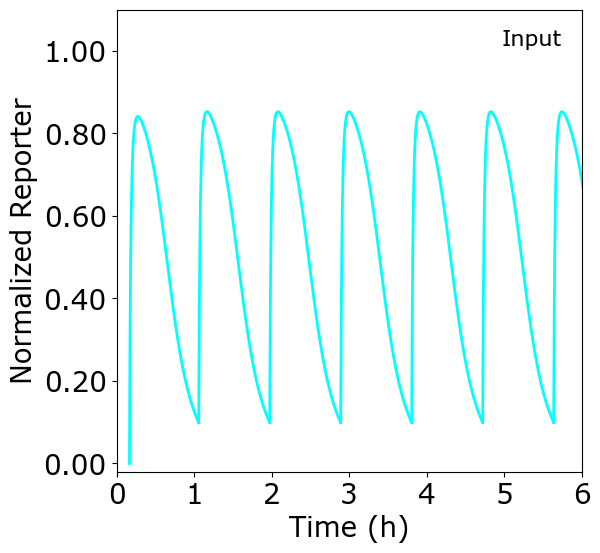

In [6]:
# Simulate
try:
    # import numpy as np
    import pylab as plt
    
    t_max = 400
    t_start = 10/60 #hr
    t_now = t_start

    rna_min = 0.5

    while t_now < t_max:
        # Simulating the model - example for 1 hours
        timepoints_2 = np.linspace(t_now,t_now+1,1001)*3600 

        # Create an initial condition so A has a non-zero value
        if t_now==t_start:
            initial_concentration_dict = {'rna_Input_k_i': 100, 'dna_Gate_i_j':50,
                                          'protein_RNAseH': 8530}

        else:
            # new_ic_dict = {}
            for col in R_t.columns:
                molecule = col
                if col == 'rna_Input_k_i':
                    value= R_t[col][1]+100
                    initial_concentration_dict.update({molecule: value})
                elif col !='time':
                    value= R_t[col][1]
                    initial_concentration_dict.update({molecule: value})
        
        # This function can also take a filename keyword to save the file at the same time
        R = CRN_pulse.simulate_with_bioscrape_via_sbml(timepoints = timepoints_2,
                                                       initial_condition_dict = initial_concentration_dict)
        
        R_t = R[(R['rna_Input_k_i']<=rna_min) & (R['dna_Output_i_j_ss']<=5)].reset_index(drop=True)
        t_now = R_t['time'].reset_index(drop=True)[1]/3600    

        # Results are in a Pandas Dictionary and can be accessed via string-names of species
        R_plot= R[R['time']<=t_now*3600].reset_index(drop=True)
        plt.plot(R_plot['time']/3600, R_plot['dna_Output_i_j_ss']/50,
                 color = 'cyan', linewidth = 2)

    plt.xlim(0,400)
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")

FormatPlot(ylabel='Normalized Reporter',ymax = 1.1, fig_name= 'RNaseH_pulse_FigMM')    

# Computing environment

In [7]:
%load_ext watermark
%watermark -v -p bioscrape,bokeh,jupyterlab,biocrnpyler

Python implementation: CPython
Python version       : 3.12.12
IPython version      : 9.12.0

bioscrape  : 1.2.1
bokeh      : 3.9.1
jupyterlab : 4.5.0
biocrnpyler: 1.3.2

